In [ ]:

import pandas as pd

df = pd.read_excel('/content/Online Retail.xlsx')

print("Dataset loaded successfully!")

display(df.head())


FileNotFoundError: [Errno 2] No such file or directory: '/content/Online Retail.xlsx'

In [ ]:

import pandas as pd

df = pd.read_excel('/Online Retail.xlsx')

print("Dataset loaded successfully!")
display(df.head())


Dataset loaded successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:

# 1. Check number of rows and columns
print("Dataset Shape:", df.shape)

# 2. Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types
print("\nData Types:")
print(df.dtypes)

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# 6. Statistical summary
print("\nStatistical Summary:")
display(df.describe().T)


Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268

Statistical Summary:


,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


In [6]:

# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Convert InvoiceDate into proper datetime format
df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate']
)

# Display the updated shape
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

# Check duplicates again
print("Remaining duplicates:",
      df_clean.duplicated().sum())


Original dataset: (541909, 8)
Cleaned dataset: (536641, 8)
Remaining duplicates: 0


In [7]:

# Check cancelled invoices
cancelled = df_clean['InvoiceNo'].astype(str).str.startswith('C')

print("Cancelled invoices:", cancelled.sum())

# Check negative quantities
print("Negative quantities:",
      (df_clean['Quantity'] < 0).sum())

# Check zero or negative prices
print("Invalid prices:",
      (df_clean['UnitPrice'] <= 0).sum())

# Check missing customer IDs
print("Missing CustomerIDs:",
      df_clean['CustomerID'].isnull().sum())


Cancelled invoices: 9251
Negative quantities: 10587
Invalid prices: 2512
Missing CustomerIDs: 135037


In [8]:

# Create a Revenue column
df_clean['Revenue'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

# Display selected columns
display(
    df_clean[
        ['InvoiceNo', 'Description',
         'Quantity', 'UnitPrice', 'Revenue']
    ].head(10)
)


,InvoiceNo,Description,Quantity,UnitPrice,Revenue
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,WHITE METAL LANTERN,6,3.39,20.34
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34
5,536365,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30
6,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50
7,536366,HAND WARMER UNION JACK,6,1.85,11.10
8,536366,HAND WARMER RED POLKA DOT,6,1.85,11.10
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08


In [9]:

total_revenue = df_clean['Revenue'].sum()

print("Total Revenue: £", round(total_revenue, 2))


Total Revenue: £ 9726006.95


In [10]:

top_products = (
    df_clean.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)


,Revenue
Description,
DOTCOM POSTAGE,206245.48
REGENCY CAKESTAND 3 TIER,164459.49
WHITE HANGING HEART T-LIGHT HOLDER,99612.42
PARTY BUNTING,98243.88
JUMBO BAG RED RETROSPOT,92175.79
RABBIT NIGHT LIGHT,66661.63
POSTAGE,66230.64
PAPER CHAIN KIT 50'S CHRISTMAS,63715.24
ASSORTED COLOUR BIRD ORNAMENT,58792.42


In [11]:

# Keep valid sales transactions
valid_sales = df_clean[
    (~df_clean['InvoiceNo'].astype(str).str.startswith('C')) &
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

# Group sales by month
monthly_sales = (
    valid_sales.groupby(
        valid_sales['InvoiceDate'].dt.to_period('M')
    )['Revenue'].sum()
)

# Display monthly sales
display(monthly_sales)


,Revenue
InvoiceDate,
2010-12,821452.730
2011-01,689811.610
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,757841.380


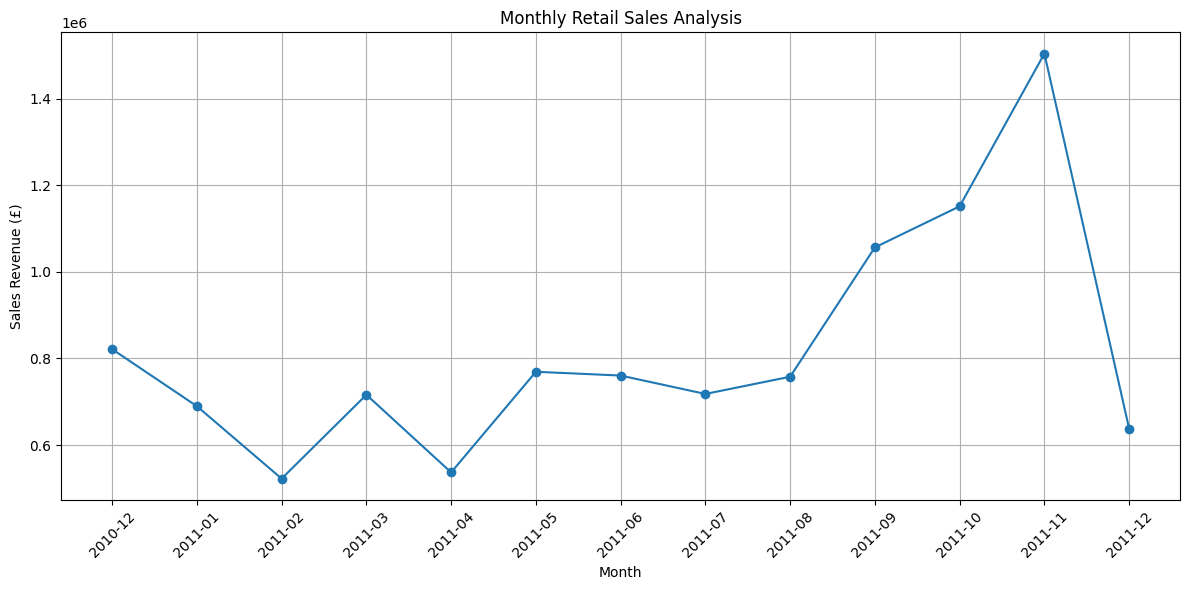

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Retail Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Sales Revenue (£)')
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()


In [13]:

# Calculate total revenue for each country
country_sales = (
    valid_sales.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 countries
display(country_sales.head(10))


,Revenue
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


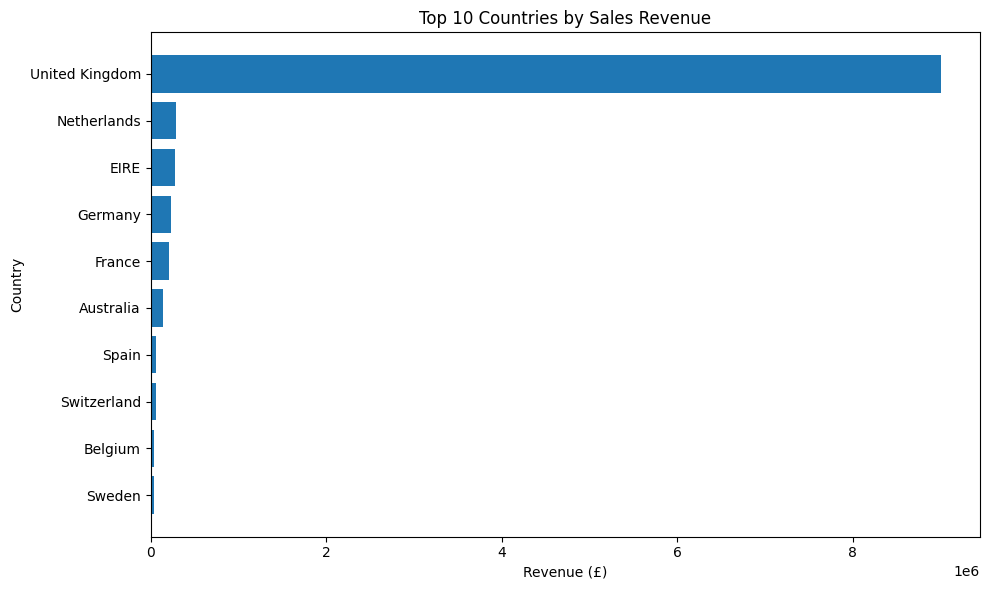

In [14]:

# Select the top 10 countries
top_countries = country_sales.head(10)

# Create bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_countries.index[::-1],
    top_countries.values[::-1]
)

plt.title('Top 10 Countries by Sales Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Country')

plt.tight_layout()
plt.show()


In [15]:

# Group transactions by invoice number
order_summary = valid_sales.groupby('InvoiceNo').agg(
    OrderRevenue=('Revenue', 'sum'),
    TotalItems=('Quantity', 'sum')
)

# Calculate order statistics
total_orders = order_summary.shape[0]

average_order_value = order_summary['OrderRevenue'].mean()

average_items_per_order = order_summary['TotalItems'].mean()

print("Total Orders:", total_orders)

print("Average Order Value: £",
      round(average_order_value, 2))

print("Average Items Per Order:",
      round(average_items_per_order, 2))


Total Orders: 19960
Average Order Value: £ 533.17
Average Items Per Order: 279.18


In [16]:

# Remove records without CustomerID
customer_data = valid_sales.dropna(
    subset=['CustomerID']
)

# Calculate revenue per customer
customer_sales = (
    customer_data.groupby('CustomerID')
    .agg(
        TotalRevenue=('Revenue', 'sum'),
        TotalOrders=('InvoiceNo', 'nunique')
    )
    .sort_values(
        by='TotalRevenue',
        ascending=False
    )
)

# Display top 10 customers
display(customer_sales.head(10))

# Count unique identified customers
print(
    "Total Identified Customers:",
    customer_data['CustomerID'].nunique()
)


,TotalRevenue,TotalOrders
CustomerID,,
14646.0,280206.02,73
18102.0,259657.30,60
17450.0,194390.79,46
16446.0,168472.50,2
14911.0,143711.17,201
12415.0,124914.53,21
14156.0,117210.08,55
17511.0,91062.38,31
16029.0,80850.84,63


Total Identified Customers: 4338


In [17]:

# Group data by product
product_summary = (
    valid_sales.groupby(['StockCode', 'Description'])
    .agg(
        TotalQuantity=('Quantity', 'sum'),
        TotalRevenue=('Revenue', 'sum'),
        NumberOfOrders=('InvoiceNo', 'nunique')
    )
    .reset_index()
)

# Sort by quantity sold
top_quantity = product_summary.sort_values(
    by='TotalQuantity',
    ascending=False
)

# Display top 10 products by quantity
display(top_quantity.head(10))


,StockCode,Description,TotalQuantity,TotalRevenue,NumberOfOrders
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
2769,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,535
3761,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2089
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,104284.24,2189
1051,22197,POPCORN HOLDER,36749,34288.67,803
370,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,1320
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1455
1951,23084,RABBIT NIGHT LIGHT,30739,66870.03,994
1327,22492,MINI PAINT SET VINTAGE,26633,16937.82,380


In [18]:

top_revenue = product_summary.sort_values(
    by='TotalRevenue',
    ascending=False
)

display(
    top_revenue[
        ['Description', 'TotalRevenue', 'TotalQuantity']
    ].head(10)
)


,Description,TotalRevenue,TotalQuantity
4150,DOTCOM POSTAGE,206248.77,706
1262,REGENCY CAKESTAND 3 TIER,174156.54,13851
2590,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3773,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580
2669,PARTY BUNTING,99445.23,18283
3761,JUMBO BAG RED RETROSPOT,94159.81,48371
2045,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
4153,POSTAGE,78101.88,3150
4151,Manual,77750.27,6984
1951,RABBIT NIGHT LIGHT,66870.03,30739


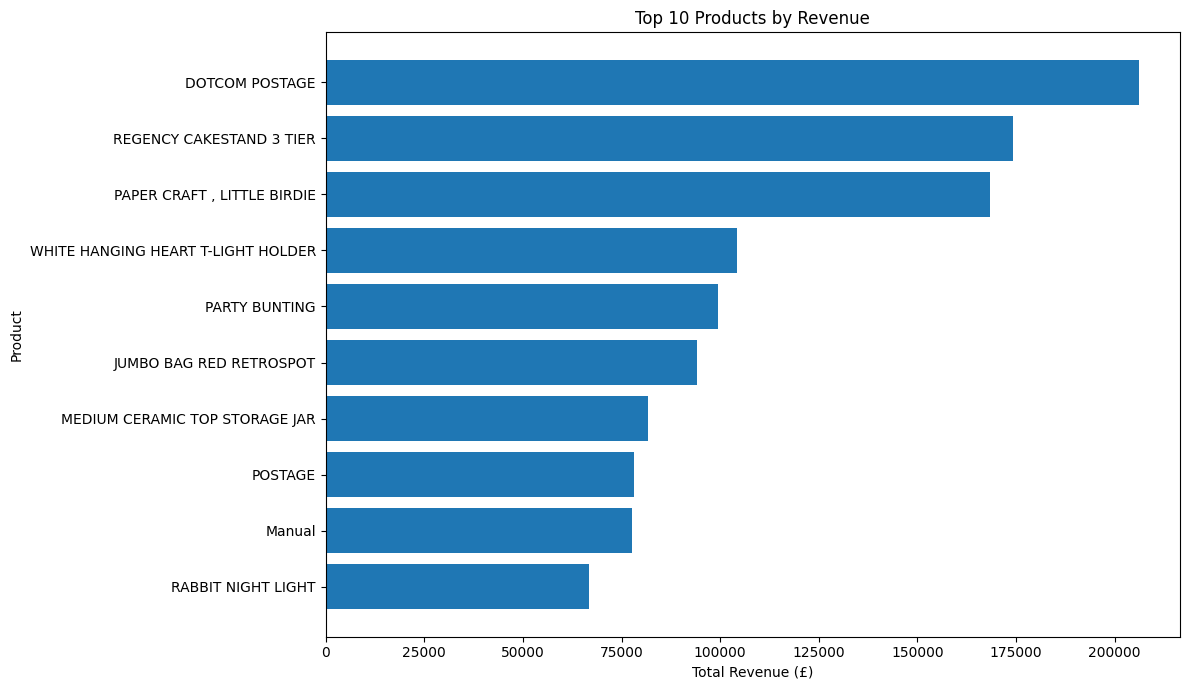

In [19]:

# Select top 10 products by revenue
top_10 = top_revenue.head(10).sort_values(
    by='TotalRevenue'
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10['Description'],
    top_10['TotalRevenue']
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Product')

plt.tight_layout()
plt.show()


In [20]:

# Create a copy with weekday and hour information
time_data = valid_sales.copy()

time_data['Weekday'] = time_data['InvoiceDate'].dt.day_name()

time_data['Hour'] = time_data['InvoiceDate'].dt.hour

# Count unique orders by weekday and hour
orders_by_time = time_data.pivot_table(
    index='Weekday',
    columns='Hour',
    values='InvoiceNo',
    aggfunc='nunique',
    fill_value=0
)

# Arrange weekdays in calendar order
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

orders_by_time = orders_by_time.reindex(
    weekday_order,
    fill_value=0
)

display(orders_by_time)


Hour,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Weekday,,,,,,,,,,,,,,,
Monday,0,4,89,275,353,356,497,453,396,367,240,94,2,0,0
Tuesday,0,5,118,315,416,428,556,502,420,456,212,117,9,0,0
Wednesday,0,5,116,303,448,431,629,509,453,426,263,104,0,2,1
Thursday,1,9,122,306,462,390,595,496,472,452,351,261,179,135,16
Friday,0,6,121,283,457,401,482,431,406,295,155,91,2,9,1
Saturday,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Sunday,0,0,0,2,225,390,461,362,310,340,114,0,0,0,0


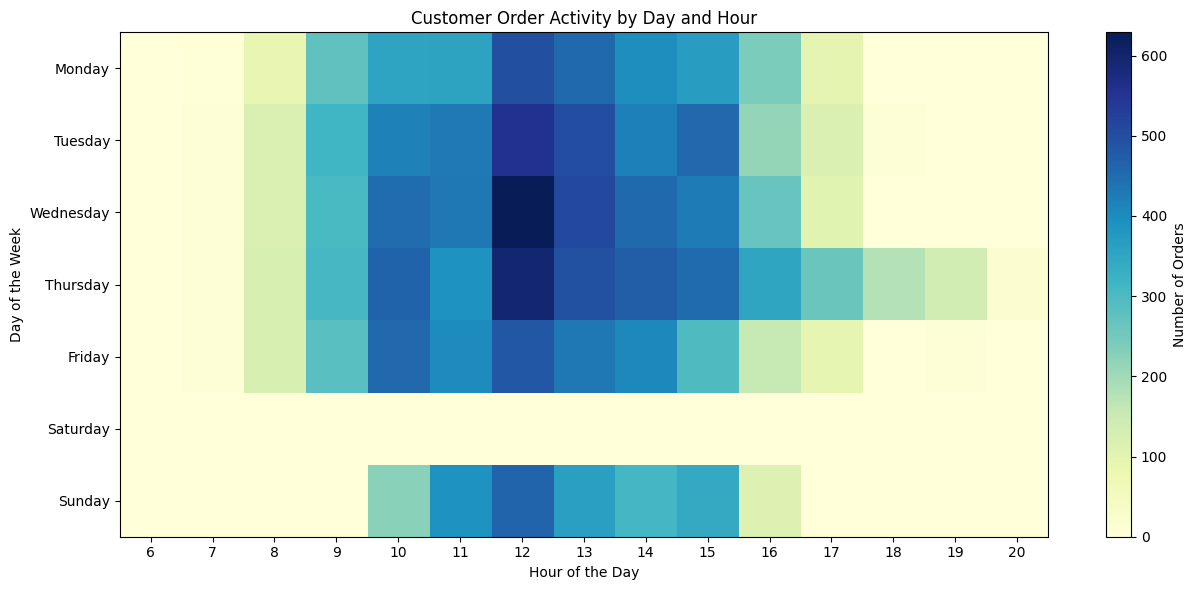

In [21]:

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 6))

plt.imshow(
    orders_by_time,
    aspect='auto',
    cmap='YlGnBu'
)

plt.colorbar(label='Number of Orders')

plt.xticks(
    range(len(orders_by_time.columns)),
    orders_by_time.columns
)

plt.yticks(
    range(len(orders_by_time.index)),
    orders_by_time.index
)

plt.title('Customer Order Activity by Day and Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Day of the Week')

plt.tight_layout()
plt.show()


In [22]:

# Overall business performance
total_sales = valid_sales['Revenue'].sum()
total_orders = valid_sales['InvoiceNo'].nunique()
average_order = total_sales / total_orders

# Best and worst sales months
best_month = monthly_sales.idxmax()
worst_month = monthly_sales.idxmin()

# Highest revenue country
best_country = country_sales.index[0]
best_country_revenue = country_sales.iloc[0]

# Highest revenue product
best_product = top_revenue.iloc[0]['Description']
best_product_revenue = top_revenue.iloc[0]['TotalRevenue']

# Most units sold product
popular_product = top_quantity.iloc[0]['Description']

# Number of identified customers
total_customers = valid_sales['CustomerID'].nunique()

# Print business findings
print("========== BUSINESS INSIGHTS ==========")

print("Total Revenue: £", round(total_sales, 2))
print("Total Orders:", total_orders)
print("Average Order Value: £", round(average_order, 2))

print("\nBest Sales Month:", best_month)
print("Lowest Sales Month:", worst_month)

print("\nHighest Revenue Country:", best_country)
print("Country Revenue: £", round(best_country_revenue, 2))

print("\nHighest Revenue Product:", best_product)
print("Product Revenue: £", round(best_product_revenue, 2))

print("\nMost Units Sold Product:", popular_product)

print("\nIdentified Customers:", total_customers)


========== BUSINESS INSIGHTS ==========
Total Revenue: £ 10642110.8
Total Orders: 19960
Average Order Value: £ 533.17

Best Sales Month: 2011-11
Lowest Sales Month: 2011-02

Highest Revenue Country: United Kingdom
Country Revenue: £ 9001744.09

Highest Revenue Product: DOTCOM POSTAGE
Product Revenue: £ 206248.77

Most Units Sold Product: PAPER CRAFT , LITTLE BIRDIE

Identified Customers: 4338
